# Titanic: Cây quyết định và rừng ngẫu nhiên
## 1. Import lib

In [1]:

import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)
RANDOM_STATE = 42

## 2. Đọc và kiểm tra dữ liệu


In [2]:
DATA_PATH = Path("../data/train.csv")  
# Nếu kernel chạy tại Downloads, sửa đường dẫn sau rồi bỏ dấu #:
# DATA_PATH = Path(r"C:\Users\thanh\Desktop\Machine Learning\kaggle\Red-Wine-Quanlity\data\train.csv")
if DATA_PATH is None:
    candidates = [p for root in [Path.cwd(), *Path.cwd().parents]
                  for p in [root / 'data' / 'train.csv', root / 'train.csv']]
    if Path('/kaggle/input').exists():
        candidates.extend(sorted(Path('/kaggle/input').rglob('train.csv')))
    DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None or not Path(DATA_PATH).is_file():
    raise FileNotFoundError(f'Không tìm thấy Titanic train.csv. CWD: {Path.cwd()}. Hãy nhập đường dẫn tuyệt đối vào DATA_PATH.')
DATA_PATH = Path(DATA_PATH)
df = pd.read_csv(DATA_PATH)
required = ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
missing_columns = set(required) - set(df.columns)
if missing_columns:
    raise ValueError(f'Thiếu cột: {missing_columns}. Hãy chọn dữ liệu Titanic train.csv.')
if df['Survived'].isna().any() or not set(df['Survived'].unique()).issubset({0, 1}):
    raise ValueError('Survived phải có nhãn 0/1 và không được thiếu.')
print('Kích thước:', df.shape)
print('Số dòng trùng toàn bộ:', df.duplicated().sum())
display(df.head())
display(df[required].isna().sum().rename('Số giá trị thiếu').to_frame())
display(df['Survived'].value_counts().sort_index().rename('Số hành khách').to_frame())

Kích thước: (891, 12)
Số dòng trùng toàn bộ: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,Số giá trị thiếu
Survived,0
Pclass,0
Sex,0
Age,177
SibSp,0
Parch,0
Fare,0
Embarked,2


,Số hành khách
Survived,
0,549
1,342


## 2. Chọn đặc trưng và chia dữ liệu


In [3]:
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']
features = numeric_features + categorical_features
X = df[features].copy()
y = df['Survived'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

Train: (712, 7) | Test: (179, 7)


## 3. Xây dựng và tối ưu cây quyết định, rừng ngẫu nhiên
Theo các nhiệm vụ 1–3 của bài mẫu trong PDF:
- Cây quyết định: khảo sát max_depth = 1, 2, 4, 6, 8, 10, 12.
- Rừng ngẫu nhiên: khảo sát n_estimators từ 10 đến 100, bước 10; giữ max_depth = 3 để khảo sát riêng ảnh hưởng số cây, giống bài mẫu.
- GridSearchCV dùng ROC-AUC và CV phân tầng 4 fold, có lưu điểm train để quan sát quá khớp.

Gini = 1 − Σpᵢ² là tiêu chí chọn phép chia. Số cây nhiều hơn không bảo đảm điểm tốt hơn; GridSearchCV chọn trong tập giá trị đã thử, không bảo đảm tối ưu toàn cục.

Tất cả tiền xử lý được fit riêng trong từng fold qua Pipeline. Giữ tập test riêng cho đánh giá cuối. Không cần StandardScaler cho mô hình cây.

In [4]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
dt_pipeline = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))
])
rf_pipeline = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model', RandomForestClassifier(max_depth=3, n_jobs=-1, random_state=RANDOM_STATE))
])
searches = {
    'Decision Tree': GridSearchCV(
        dt_pipeline, {'model__max_depth': [1, 2, 4, 6, 8, 10, 12]},
        scoring='roc_auc', cv=cv, refit=True, return_train_score=True,
        n_jobs=1, error_score='raise'),
    'Random Forest': GridSearchCV(
        rf_pipeline, {'model__n_estimators': list(range(10, 110, 10))},
        scoring='roc_auc', cv=cv, refit=True, return_train_score=True,
        n_jobs=1, error_score='raise')
}
models, cv_results = {}, {}
for name, search in searches.items():
    search.fit(X_train, y_train)
    models[name] = search.best_estimator_
    cv_results[name] = search.best_score_
    print(name, '| Tham số:', search.best_params_, '| CV ROC-AUC:', round(search.best_score_, 4))
selected_name = max(cv_results, key=cv_results.get)
print('Mô hình được chọn theo CV ROC-AUC:', selected_name)

Decision Tree | Tham số: {'model__max_depth': 4} | CV ROC-AUC: 0.8389
Random Forest | Tham số: {'model__n_estimators': 100} | CV ROC-AUC: 0.8644
Mô hình được chọn theo CV ROC-AUC: Random Forest


### 3.1. Khảo sát độ sâu cây quyết định
Trục tung là ROC-AUC; thanh sai số là ±1 SE = std / √4. mean_test_score trong cv_results_ là điểm validation của CV trên train, không phải điểm tập test 20%.

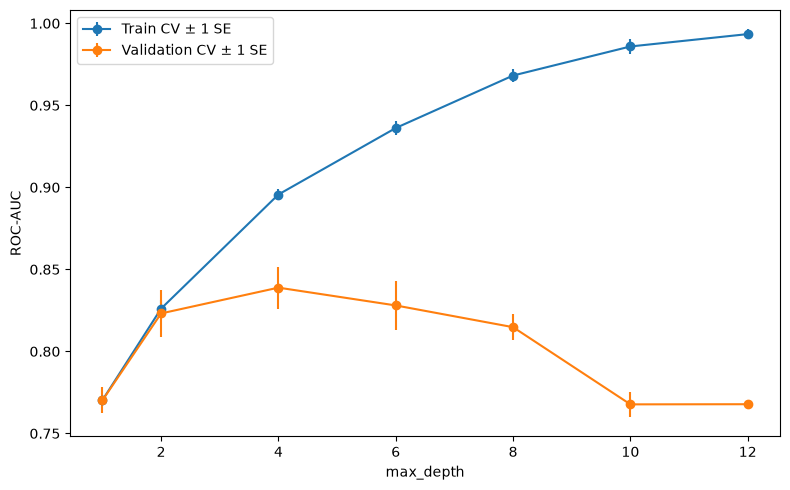

,param_model__max_depth,mean_train_score,mean_test_score,std_test_score
0,1,0.770276,0.770157,0.015773
1,2,0.826063,0.823138,0.028959
2,4,0.895639,0.838861,0.025698
3,6,0.936167,0.828011,0.029819
4,8,0.968162,0.814761,0.015753
5,10,0.985881,0.767707,0.015545
6,12,0.993419,0.767793,0.003475


In [5]:
dt_cv = pd.DataFrame(searches['Decision Tree'].cv_results_)
depths = dt_cv['param_model__max_depth'].astype(int)
plt.figure(figsize=(8, 5))
plt.errorbar(depths, dt_cv['mean_train_score'],
             yerr=dt_cv['std_train_score']/np.sqrt(cv.get_n_splits()), marker='o', label='Train CV ± 1 SE')
plt.errorbar(depths, dt_cv['mean_test_score'],
             yerr=dt_cv['std_test_score']/np.sqrt(cv.get_n_splits()), marker='o', label='Validation CV ± 1 SE')
plt.xlabel('max_depth')
plt.ylabel('ROC-AUC')
plt.legend()
plt.tight_layout()
plt.show()
display(dt_cv[['param_model__max_depth', 'mean_train_score', 'mean_test_score', 'std_test_score']])

### 3.2. Khảo sát số cây và thời gian huấn luyện
Biểu đồ trái đo thời gian fit trung bình cho mỗi fold, bao gồm tiền xử lý. Biểu đồ phải so sánh ROC-AUC validation của rừng khi thay đổi số cây. Các yếu tố khác được giữ cố định.

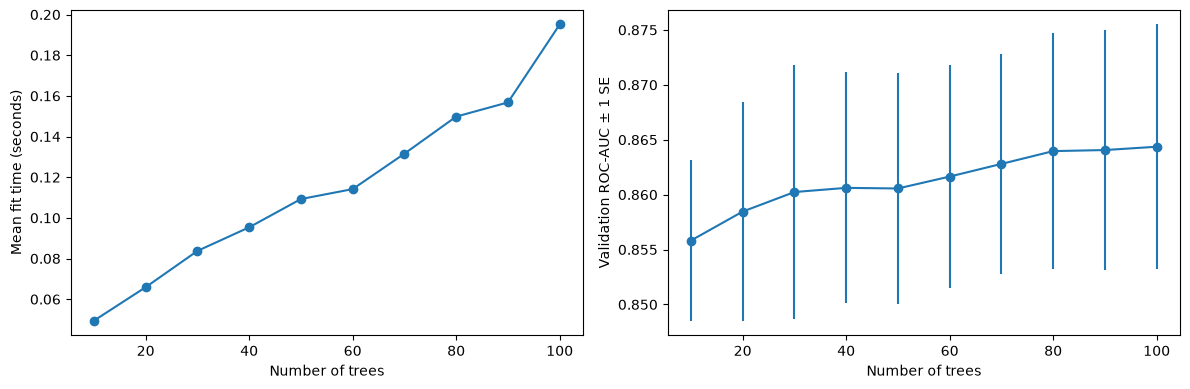

,param_model__n_estimators,mean_fit_time,mean_train_score,mean_test_score
0,10,0.049435,0.873198,0.855821
1,20,0.065895,0.875952,0.858458
2,30,0.083747,0.877229,0.860239
3,40,0.095363,0.879516,0.860617
4,50,0.109265,0.880335,0.860562
5,60,0.114150,0.880172,0.861647
6,70,0.131580,0.882074,0.862800
7,80,0.149806,0.883133,0.863964
8,90,0.156783,0.882612,0.864062
9,100,0.195121,0.883195,0.864364


In [6]:
rf_cv = pd.DataFrame(searches['Random Forest'].cv_results_)
counts = rf_cv['param_model__n_estimators'].astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(counts, rf_cv['mean_fit_time'], '-o')
axes[0].set_xlabel('Number of trees')
axes[0].set_ylabel('Mean fit time (seconds)')
axes[1].errorbar(counts, rf_cv['mean_test_score'],
                 yerr=rf_cv['std_test_score']/np.sqrt(cv.get_n_splits()), marker='o')
axes[1].set_xlabel('Number of trees')
axes[1].set_ylabel('Validation ROC-AUC ± 1 SE')
plt.tight_layout()
plt.show()
display(rf_cv[['param_model__n_estimators', 'mean_fit_time', 'mean_train_score', 'mean_test_score']])

## 4. Huấn luyện và đánh giá
Accuracy: tỉ lệ dự đoán đúng. Precision: trong những người được dự đoán sống sót, bao nhiêu thực sự sống sót. Recall: trong số người thực sự sống sót, mô hình tìm được bao nhiêu. F1 cân bằng precision và recall. ROC-AUC đánh giá khả năng phân biệt hai lớp dựa trên điểm xác suất.

So sánh accuracy trên train/test giúp quan sát quá khớp, nhưng một lần chia dữ liệu không đủ để kết luận chắc chắn mô hình nào luôn tốt hơn.


Decision Tree
                precision    recall  f1-score   support

Khong song sot       0.77      0.94      0.84       110
      Song sot       0.84      0.55      0.67        69

      accuracy                           0.79       179
     macro avg       0.81      0.74      0.76       179
  weighted avg       0.80      0.79      0.78       179


Random Forest
                precision    recall  f1-score   support

Khong song sot       0.81      0.91      0.85       110
      Song sot       0.82      0.65      0.73        69

      accuracy                           0.81       179
     macro avg       0.81      0.78      0.79       179
  weighted avg       0.81      0.81      0.81       179



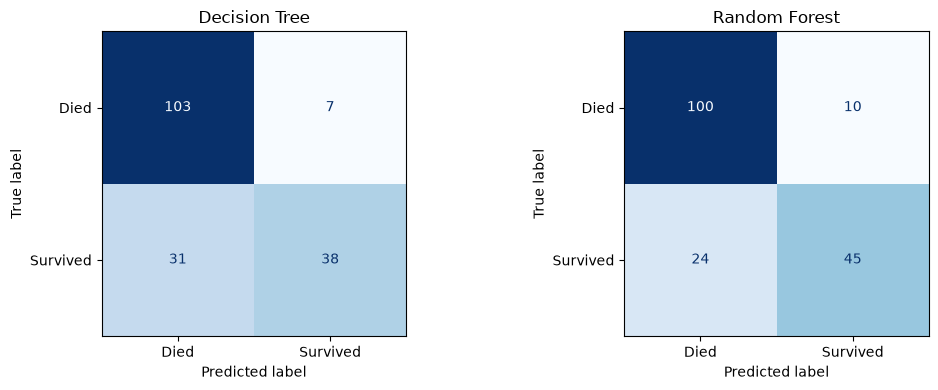

,CV ROC-AUC,Train accuracy,Test accuracy,Precision,Recall,F1,ROC-AUC,Fit seconds
Model,,,,,,,,
Decision Tree,0.8389,0.8413,0.7877,0.8444,0.5507,0.6667,0.8210,0.0146
Random Forest,0.8644,0.8188,0.8101,0.8182,0.6522,0.7258,0.8355,0.1849


Baseline đoán lớp phổ biến theo train: 0.6145251396648045


In [7]:
rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        'Model': name,
        'CV ROC-AUC': cv_results[name],
        'Train accuracy': model.score(X_train, y_train),
        'Test accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'Fit seconds': fit_seconds
    })
    print('\n' + name)
    print(classification_report(y_test, y_pred, labels=[0, 1],
          target_names=['Khong song sot', 'Song sot'], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=['Died', 'Survived'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()
results = pd.DataFrame(rows).set_index('Model')
display(results.round(4))
print('Baseline đoán lớp phổ biến theo train:', accuracy_score(
    y_test, np.full(len(y_test), y_train.mode().iloc[0])))

## 5. Vẽ cây quyết định
Điều kiện đúng: sang nhánh trái; sai: sang nhánh phải. samples là số mẫu huấn luyện ở nút; value biểu diễn phân bố lớp; class là lớp dự đoán. Đặc trưng one-hot có ngưỡng 0.5 để phân biệt có/không thuộc một nhóm.

Hình chỉ hiển thị 4 tầng đầu nếu cây tối ưu sâu hơn 3; dấu (...) biểu thị phần được thu gọn. Quy tắc dạng chữ ở dưới gồm toàn bộ cây. Dùng plot_tree thay Graphviz để không cần cài chương trình Graphviz; cả hai hiển thị cùng cấu trúc cây.

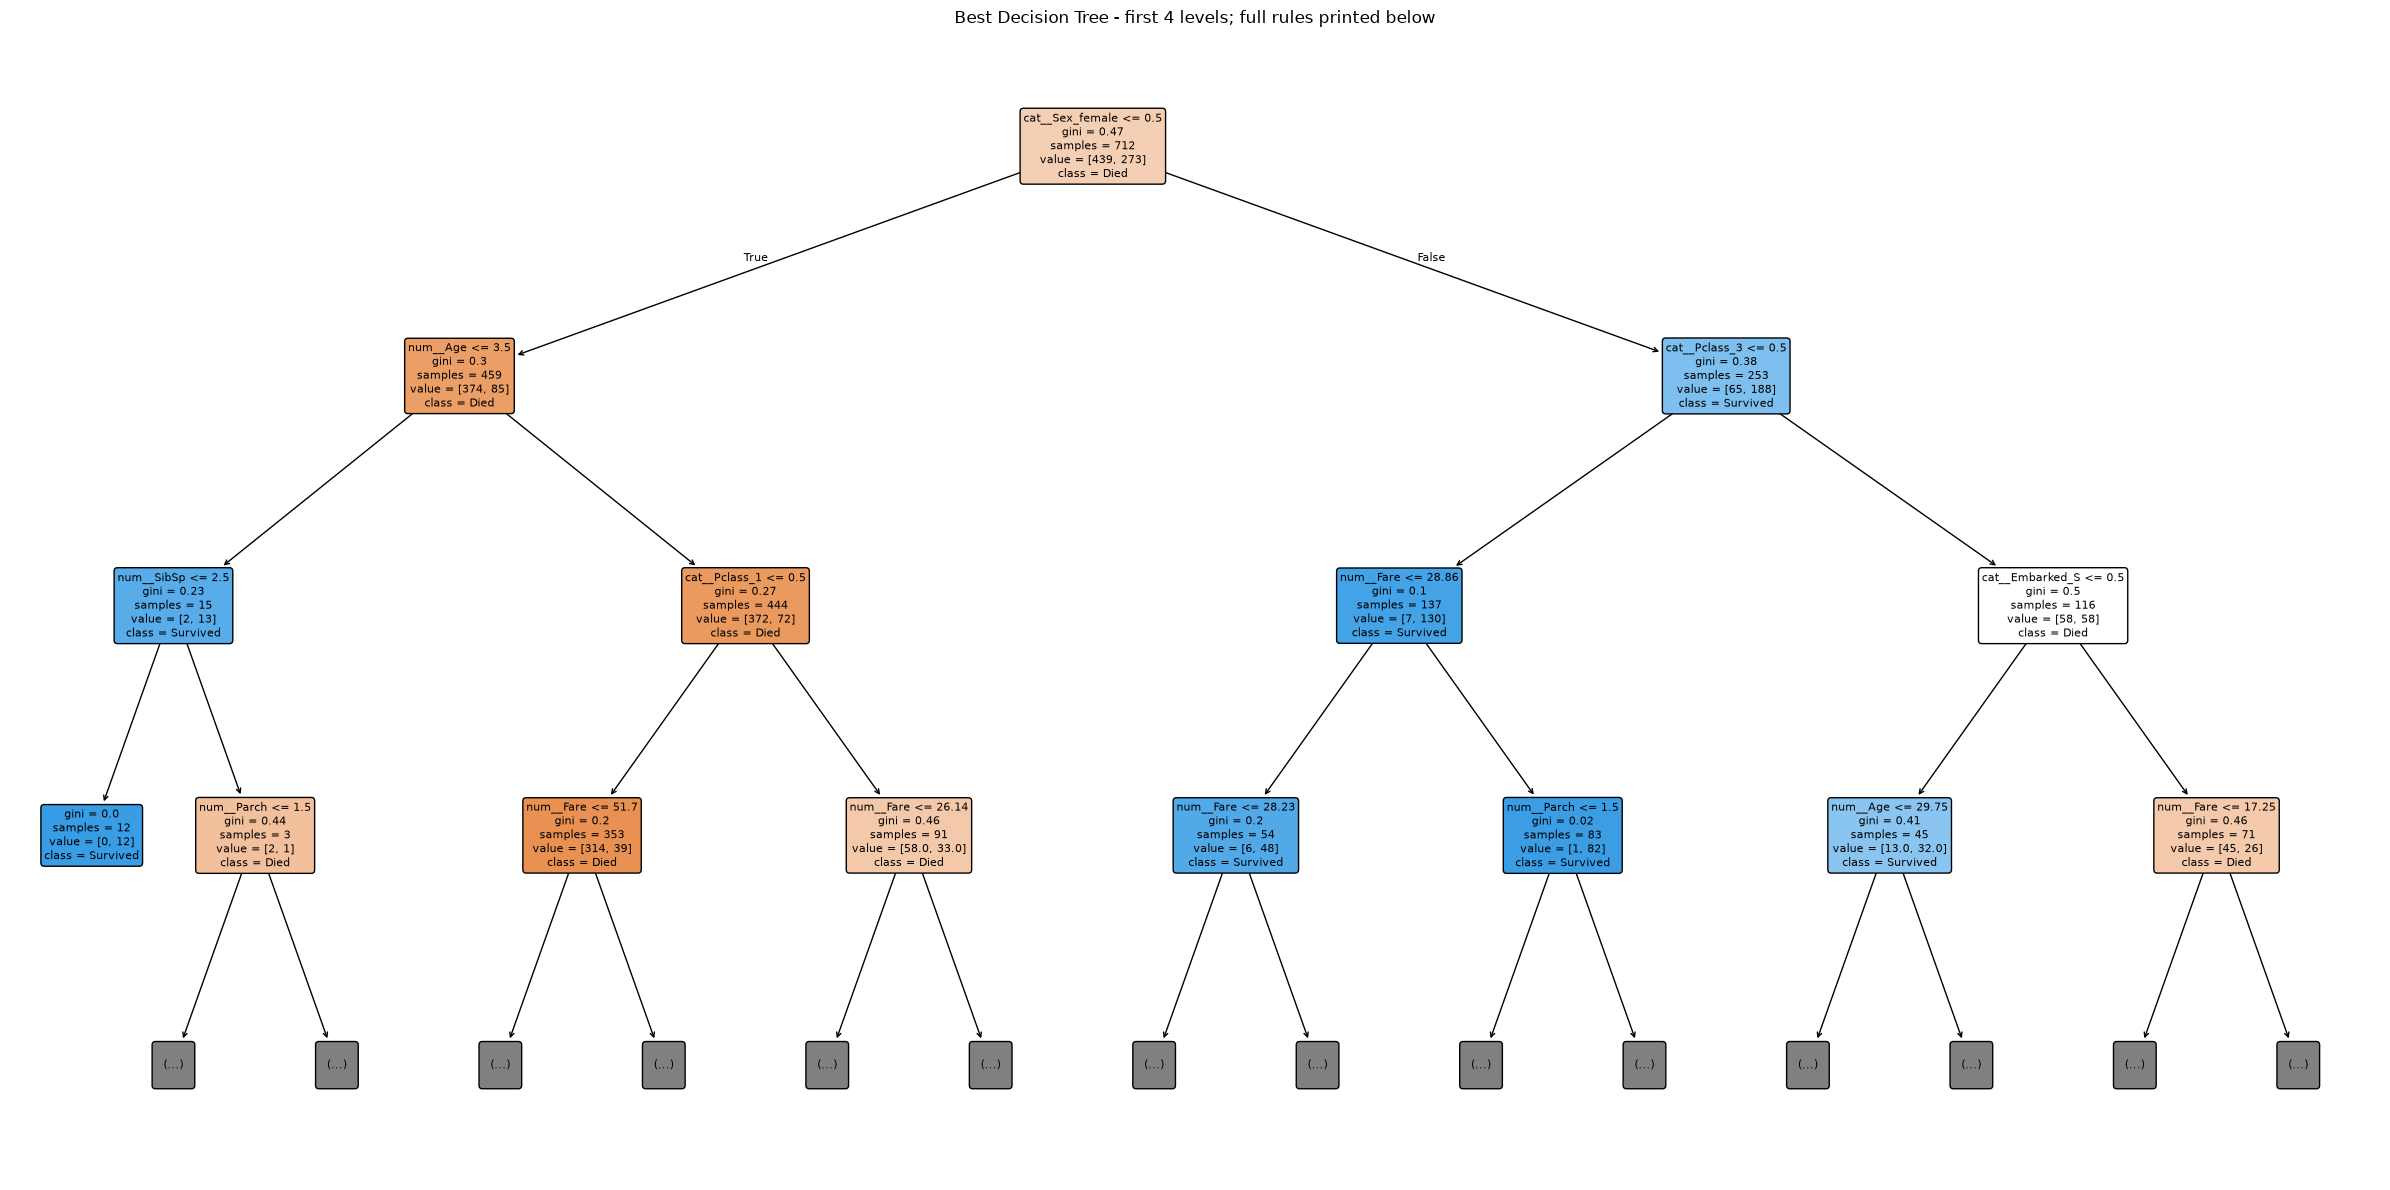

|--- cat__Sex_female <= 0.50
|   |--- num__Age <= 3.50
|   |   |--- num__SibSp <= 2.50
|   |   |   |--- class: 1
|   |   |--- num__SibSp >  2.50
|   |   |   |--- num__Parch <= 1.50
|   |   |   |   |--- class: 0
|   |   |   |--- num__Parch >  1.50
|   |   |   |   |--- class: 1
|   |--- num__Age >  3.50
|   |   |--- cat__Pclass_1 <= 0.50
|   |   |   |--- num__Fare <= 51.70
|   |   |   |   |--- class: 0
|   |   |   |--- num__Fare >  51.70
|   |   |   |   |--- class: 0
|   |   |--- cat__Pclass_1 >  0.50
|   |   |   |--- num__Fare <= 26.14
|   |   |   |   |--- class: 0
|   |   |   |--- num__Fare >  26.14
|   |   |   |   |--- class: 0
|--- cat__Sex_female >  0.50
|   |--- cat__Pclass_3 <= 0.50
|   |   |--- num__Fare <= 28.86
|   |   |   |--- num__Fare <= 28.23
|   |   |   |   |--- class: 1
|   |   |   |--- num__Fare >  28.23
|   |   |   |   |--- class: 0
|   |   |--- num__Fare >  28.86
|   |   |   |--- num__Parch <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- num__Parch >  1.50
|   |

In [8]:
dt = models['Decision Tree']
feature_names = dt.named_steps['preprocess'].get_feature_names_out()
plt.figure(figsize=(24, 12))
plot_tree(dt.named_steps['model'], feature_names=feature_names,
          class_names=['Died', 'Survived'], max_depth=3, filled=True, rounded=True,
          fontsize=8, precision=2)
plt.title('Best Decision Tree - first 4 levels; full rules printed below')
plt.tight_layout()
plt.show()
print(export_text(dt.named_steps['model'], feature_names=list(feature_names)))

## 6. Xem một cây trong rừng và độ quan trọng đặc trưng
Một rừng có nhiều cây nên không vẽ toàn bộ rừng trên cùng hình. Dưới đây là ba tầng đầu của cây đầu tiên.

Feature importance dựa trên mức giảm impurity, không chứng minh quan hệ nhân quả và có thể thiên lệch về các đặc trưng có nhiều giá trị khác nhau.

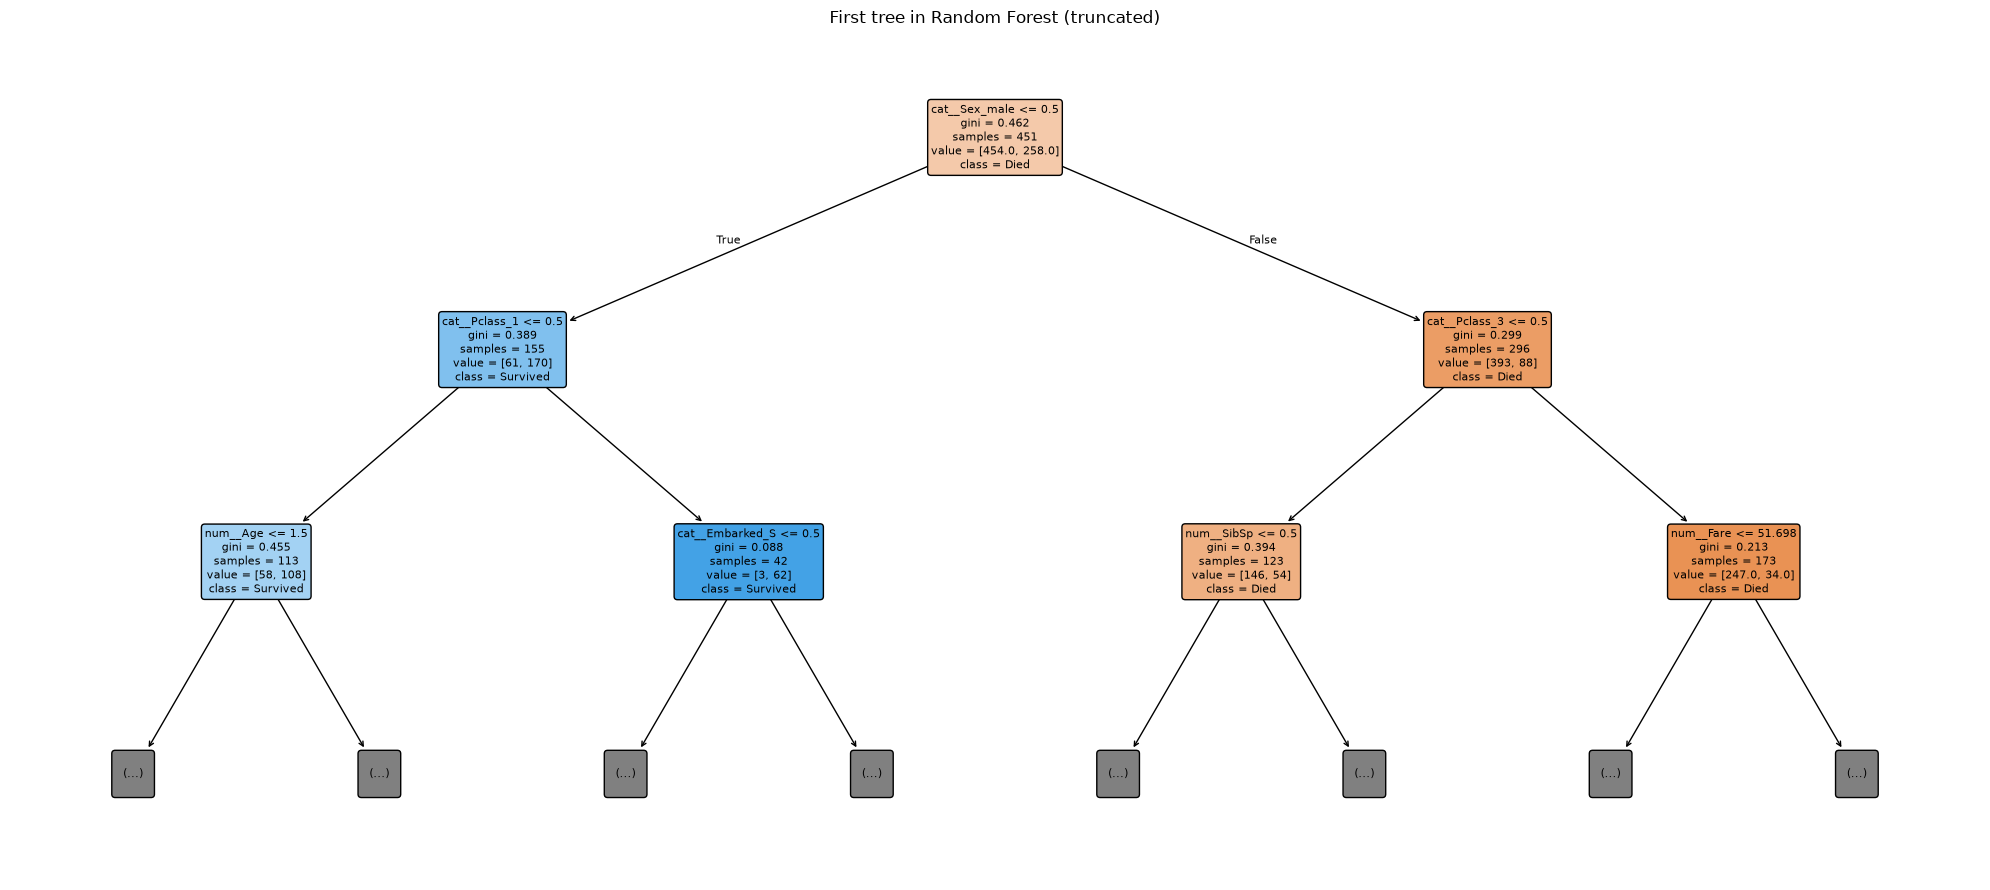

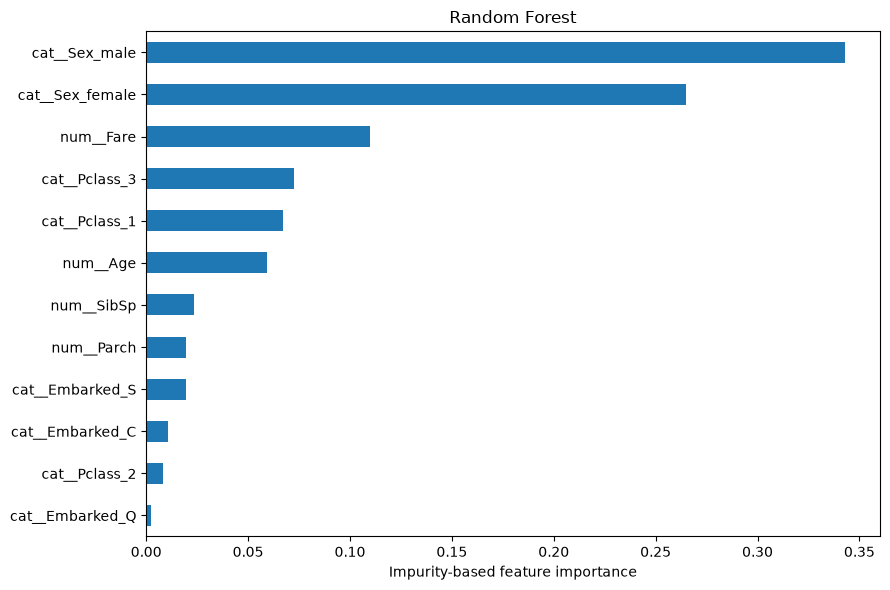

,Importance
cat__Sex_male,0.342952
cat__Sex_female,0.264807
num__Fare,0.109642
cat__Pclass_3,0.072329
cat__Pclass_1,0.066922
num__Age,0.059500
num__SibSp,0.023274
num__Parch,0.019613
cat__Embarked_S,0.019371
cat__Embarked_C,0.010859


In [9]:
rf = models['Random Forest']
rf_names = rf.named_steps['preprocess'].get_feature_names_out()
plt.figure(figsize=(20, 9))
plot_tree(rf.named_steps['model'].estimators_[0], feature_names=rf_names,
          class_names=['Died', 'Survived'], max_depth=2,
          filled=True, rounded=True, fontsize=8)
plt.title('First tree in Random Forest (truncated)')
plt.tight_layout()
plt.show()
importance = pd.Series(rf.named_steps['model'].feature_importances_, index=rf_names)
importance.sort_values().plot.barh(figsize=(9, 6))
plt.xlabel('Impurity-based feature importance')
plt.title('Random Forest')
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).to_frame('Importance'))

## 7. Dự đoán cho hành khách mới
Dùng mô hình đã chọn theo cross-validation. Xác suất chỉ là ước lượng của mô hình.

In [10]:
new_passengers = pd.DataFrame([
    {'Age': 25, 'SibSp': 0, 'Parch': 0, 'Fare': 80,
     'Pclass': 1, 'Sex': 'female', 'Embarked': 'S'},
    {'Age': 30, 'SibSp': 0, 'Parch': 0, 'Fare': 8,
     'Pclass': 3, 'Sex': 'male', 'Embarked': 'S'}
])[features]
selected_model = models[selected_name]
predictions = new_passengers.copy()
predictions['Predicted_Survived'] = selected_model.predict(new_passengers)
predictions['Survival_probability'] = selected_model.predict_proba(new_passengers)[:, 1]
display(predictions)

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Predicted_Survived,Survival_probability
0,25,0,0,80,1,female,S,1,0.881245
1,30,0,0,8,3,male,S,0,0.139227
